# WiFi CSI Human Activity Recognition — CNN-GRU with Self-Attention

**Task.** Binary classification of 2-second WiFi CSI amplitude windows ($52 \times 200$):
`action` (person moving) vs `noaction` (person present but still).

**Hardware.** USRP N210 passively sniffing an 802.11 link (MacBook $\rightarrow$ Android hotspot),
channel 11 (2.462 GHz), 20 MHz, single antenna, 52 OFDM subcarriers, **amplitude only**.

**Why this notebook exists.** The ImgFi reference pipeline
(`Action_NoAction_imgfi.ipynb`) converts *each subcarrier independently* into a
$224\times224$ recurrence-plot image, classifies all 52 with a ResNet-18, and takes a
majority vote — 52 forward passes per window. This notebook instead feeds the whole
$52\times200$ matrix to a **1D CNN $\rightarrow$ BiGRU $\rightarrow$ attention** model in a
single pass, and this notebook shows *with measurements* why that is the better fit for
this data.

**Evaluation.** Leave-One-Subject-Out (LOSO): train on one person, test on the other,
both directions. Never a random split — see Section 5.

---
### Notebook map
| § | Content |
|---|---|
| 1 | Raw CSI straight from the capture CSV — what the sensor actually gives us |
| 2 | Raw $\rightarrow$ window: detrending, recurrence plots, the model's real input |
| 3 | **Why all 52 subcarriers are processed jointly** (correlation + effective rank) |
| 4 | **Is our sampling rate adequate?** (spectral analysis) |
| 5 | Dataset composition and the LOSO protocol |
| 6–9 | Preprocessing, architecture, training |
| 10–15 | Results, attention, per-take errors, honest baseline, efficiency |
| 16 | Corrected comparison against the ImgFi pipeline |

In [1]:
import os
import glob
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal as sps

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Reproducibility: the original run had no seed, so numbers moved between runs.
SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")
print(f"torch {torch.__version__}")

PILOT   = "../data/pilot"
WINDOWS = f"{PILOT}/windows"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

Using device: cuda
torch 2.12.0+cu130


## 1. Raw CSI — what the sensor actually gives us

Before any windowing, this is the physical measurement. Each decoded 802.11 frame yields
one row: a timestamp plus **52 complex channel estimates** $H_k = \mathrm{Re}_k + j\,\mathrm{Im}_k$,
one per OFDM subcarrier.

**Why 52?** In 802.11a/g at 20 MHz the OFDM symbol has 64 subcarrier slots; 12 are unused
(DC + guard bands), leaving **52 usable data/pilot subcarriers**. This is the physical layer,
not a choice we made.

**Why amplitude $|H| = \sqrt{\mathrm{Re}^2+\mathrm{Im}^2}$ and never raw phase?**
Our USRP is *not* frequency- or time-synchronised to the MacBook. Every packet therefore
carries a random carrier-frequency offset, sampling-frequency offset and timing offset,
which add an unknown, packet-varying rotation to the phase. Raw phase is effectively noise
for us. Amplitude is immune to all three.
*(The ARIL dataset — also USRP N210, also 52 subcarriers — discards phase too, even though
they had GPS-disciplined clock sync on both ends.)*

In [2]:
csv_files = sorted(glob.glob(f"{PILOT}/P01_*.csv"))
print(f"{len(csv_files)} capture files\n")

def load_capture(path):
    '''CSV -> (time_s, amplitude[n_packets, 52]).

    Every capture has exactly ONE truncated final row: the flowgraph was Ctrl+C'd
    mid-write, so the last CSV line is incomplete. We drop it explicitly.
    '''
    df = pd.read_csv(path)
    n_sc = sum(1 for c in df.columns if c.endswith("_Re"))
    cols = [f"SC{i}_Re" for i in range(n_sc)] + [f"SC{i}_Im" for i in range(n_sc)]
    before = len(df)
    df = df.dropna(subset=cols + ["Timestamp_us"])
    dropped = before - len(df)
    t = df["Timestamp_us"].to_numpy(np.int64)
    re = df[[f"SC{i}_Re" for i in range(n_sc)]].to_numpy(float)
    im = df[[f"SC{i}_Im" for i in range(n_sc)]].to_numpy(float)
    amp = np.hypot(re, im)                      # |H| : the sensing signal
    o = np.argsort(t)
    return (t[o] - t[o][0]) / 1e6, amp[o], dropped

# Inventory: true duration and packet rate come from TIMESTAMPS, not row counts.
rows = []
for f in csv_files:
    t, amp, dropped = load_capture(f)
    b = os.path.basename(f)
    rows.append({
        "file": b.replace("P01_", "").replace("_20260717", "").replace(".csv", ""),
        "class": "action" if "_action_" in b else "noaction",
        "packets": len(t),
        "duration_s": round(t[-1], 1),
        "rate_Hz": round((len(t) - 1) / t[-1], 1),
        "truncated_rows": dropped,
    })
inventory = pd.DataFrame(rows)
print(inventory.to_string(index=False))
print(f"\nMean packet rate: {inventory.rate_Hz.mean():.1f} Hz   "
      f"(min {inventory.rate_Hz.min()}, max {inventory.rate_Hz.max()})")

8 capture files



                     file    class  packets  duration_s  rate_Hz  truncated_rows
      action_amrith_mixed   action     7929       107.9     73.5               1
       action_amrith_walk   action     6707        91.8     73.0               1
  action_rishiikesh_mixed   action     5380        95.9     56.1               1
   action_rishiikesh_walk   action     7114        91.6     77.6               1
      noaction_amrith_sit noaction     6515        91.8     71.0               1
    noaction_amrith_stand noaction     6046        92.1     65.6               1
  noaction_rishiikesh_sit noaction     4679        90.9     51.5               1
noaction_rishiikesh_stand noaction     5643        89.8     62.9               1

Mean packet rate: 66.4 Hz   (min 51.5, max 77.6)


> **Note the rate.** We measure **51.5–77.6 Hz (mean 66.4)**, not the ~100 Hz the capture
> guide targets. We sniff a *real* link passively, so the rate is whatever the MacBook
> happens to emit and that `gr-ieee802-11` can decode (legacy OFDM only — 802.11n HT frames
> are dropped). Section 4 tests whether this is actually fast enough, rather than assuming.
>
> **Duration must come from timestamps.** Computing `rows / 50` (as the ImgFi notebook does)
> would report amrith's `mixed` take as 158.6 s when it is really 107.9 s.

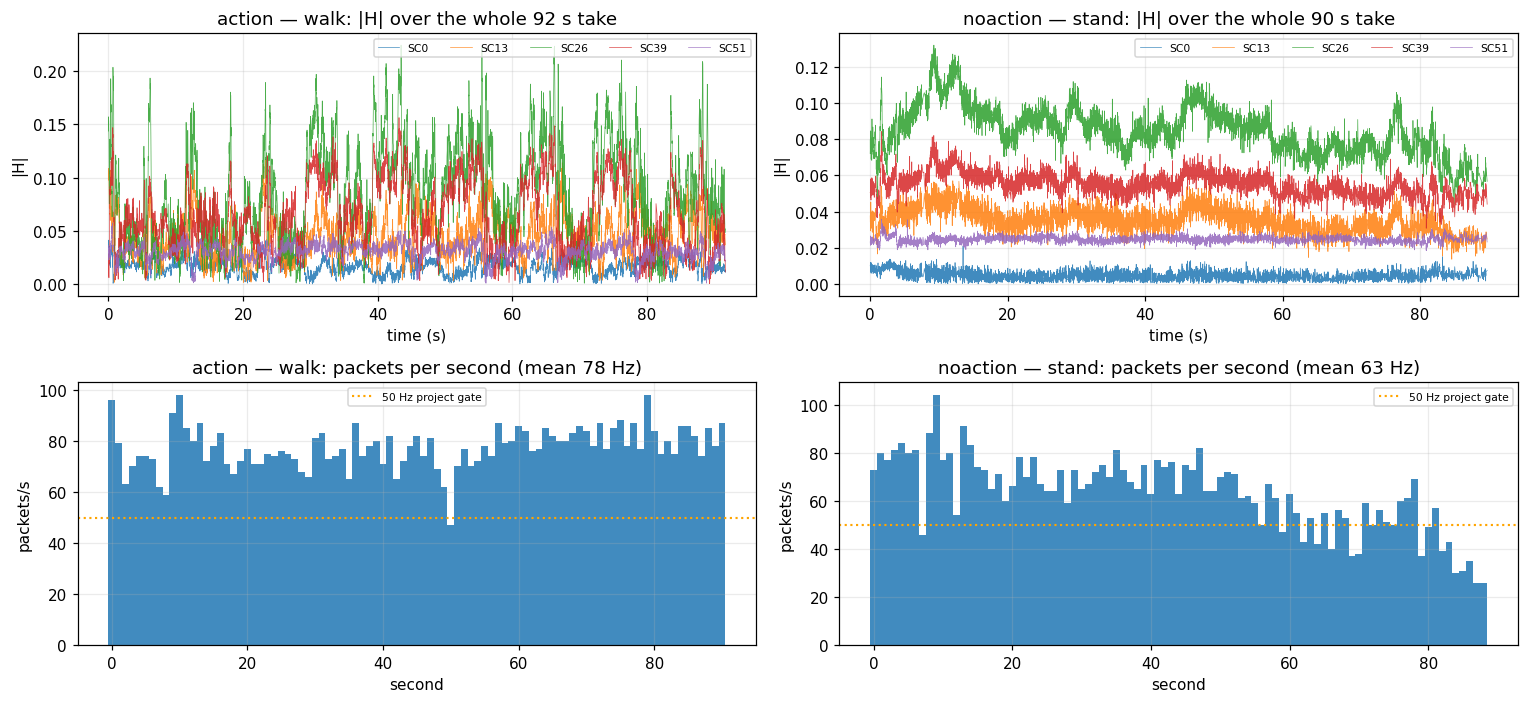

In [3]:
# One capture end-to-end: amplitude over the full take + packet-rate stability
fig, axes = plt.subplots(2, 2, figsize=(14, 6.5))

for col, (fn, title) in enumerate([
        ("P01_action_rishiikesh_20260717_walk.csv",  "action — walk"),
        ("P01_noaction_rishiikesh_20260717_stand.csv", "noaction — stand")]):
    t, amp, _ = load_capture(f"{PILOT}/{fn}")

    ax = axes[0, col]
    for sc in (0, 13, 26, 39, 51):
        ax.plot(t, amp[:, sc], lw=0.45, alpha=0.85, label=f"SC{sc}")
    ax.set_title(f"{title}: |H| over the whole {t[-1]:.0f} s take")
    ax.set_xlabel("time (s)"); ax.set_ylabel("|H|")
    ax.legend(fontsize=7, ncol=5, loc="upper right")

    ax = axes[1, col]
    per_sec = np.bincount(t.astype(int))[:-1]
    ax.bar(np.arange(len(per_sec)), per_sec, width=1.0, alpha=0.85)
    ax.axhline(50, color="orange", ls=":", lw=1.4, label="50 Hz project gate")
    ax.set_title(f"{title}: packets per second (mean {len(t)/t[-1]:.0f} Hz)")
    ax.set_xlabel("second"); ax.set_ylabel("packets/s"); ax.legend(fontsize=7)

plt.tight_layout(); plt.show()

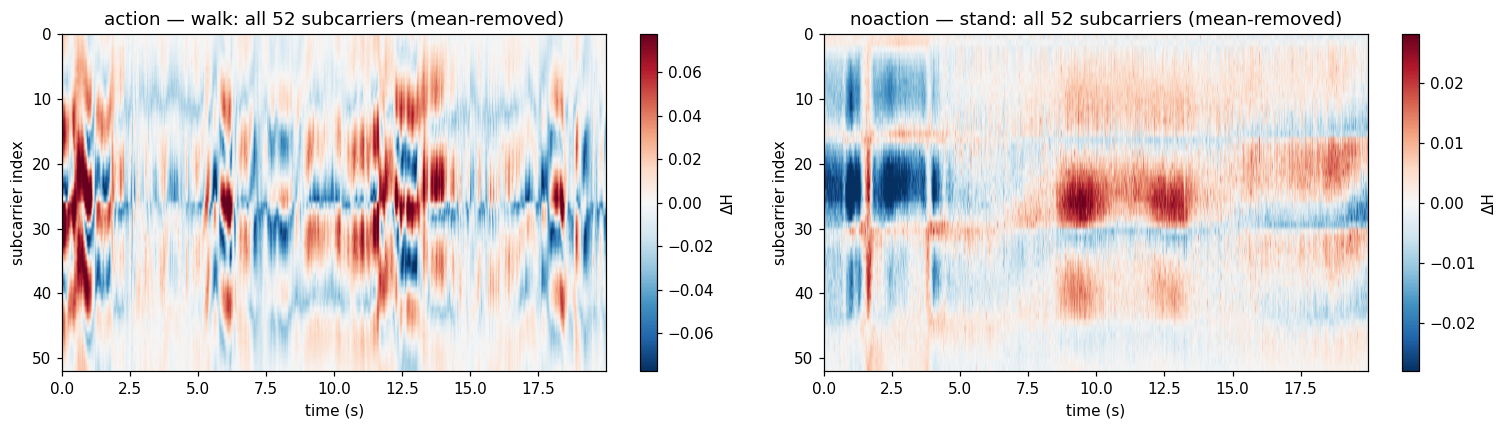

Vertical stripes = an event that hits ALL subcarriers at once (body motion).
This shared structure across subcarriers is exactly what Section 3 quantifies,
and what the ImgFi per-subcarrier split throws away.


In [4]:
# The same data as a subcarrier x time heatmap: this is the 2D structure the model exploits
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (fn, title) in zip(axes, [
        ("P01_action_rishiikesh_20260717_walk.csv",   "action — walk"),
        ("P01_noaction_rishiikesh_20260717_stand.csv", "noaction — stand")]):
    t, amp, _ = load_capture(f"{PILOT}/{fn}")
    m = t <= 20                                   # first 20 s
    d = amp[m] - amp[m].mean(axis=0, keepdims=True)   # remove static offset
    v = np.percentile(np.abs(d), 99)
    im = ax.imshow(d.T, aspect="auto", cmap="RdBu_r", vmin=-v, vmax=v,
                   extent=[0, t[m][-1], 52, 0])
    ax.set_title(f"{title}: all 52 subcarriers (mean-removed)")
    ax.set_xlabel("time (s)"); ax.set_ylabel("subcarrier index"); ax.grid(False)
    plt.colorbar(im, ax=ax, label="ΔH")
plt.tight_layout(); plt.show()

print("Vertical stripes = an event that hits ALL subcarriers at once (body motion).")
print("This shared structure across subcarriers is exactly what Section 3 quantifies,")
print("and what the ImgFi per-subcarrier split throws away.")

## 2. From raw capture to model input

`segment_windows.py` turns each capture into 2-second windows:

1. compute amplitude $|H|$ per packet;
2. take a 2 s span and **resample it onto a uniform time grid by linear interpolation**
   using the real timestamps, producing exactly $52 \times 200$;
3. skip the window if fewer than 50% of the expected packets are present.

Step 2 matters: packets arrive irregularly (median gap ≈ 12 ms, worst gap 464 ms), so
slicing by *packet count* would give windows of inconsistent physical duration.
Interpolating onto a time grid makes every window exactly 2 s of wall-clock time.

Below: raw window, detrended window, and the recurrence plot (the ImgFi representation)
for the same data.

Loaded Action Window shape: (52, 200)
Loaded No-Action Window shape: (52, 200)


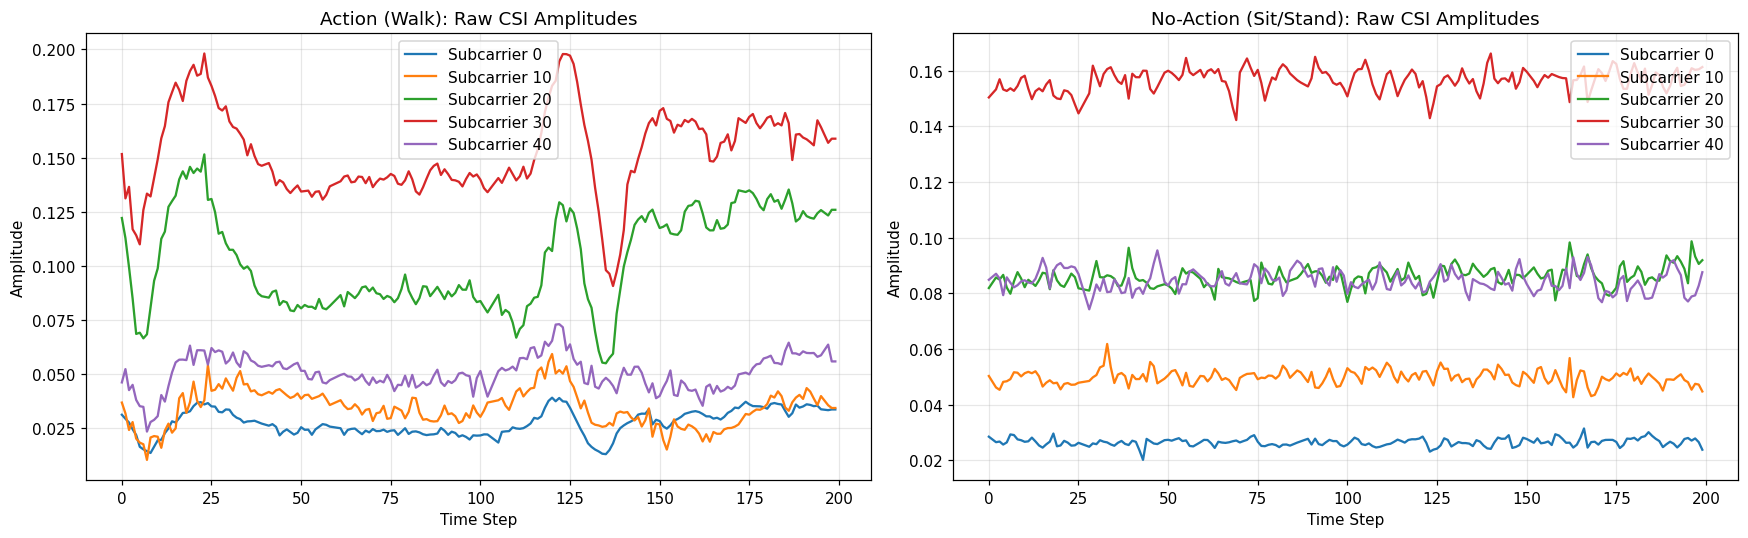

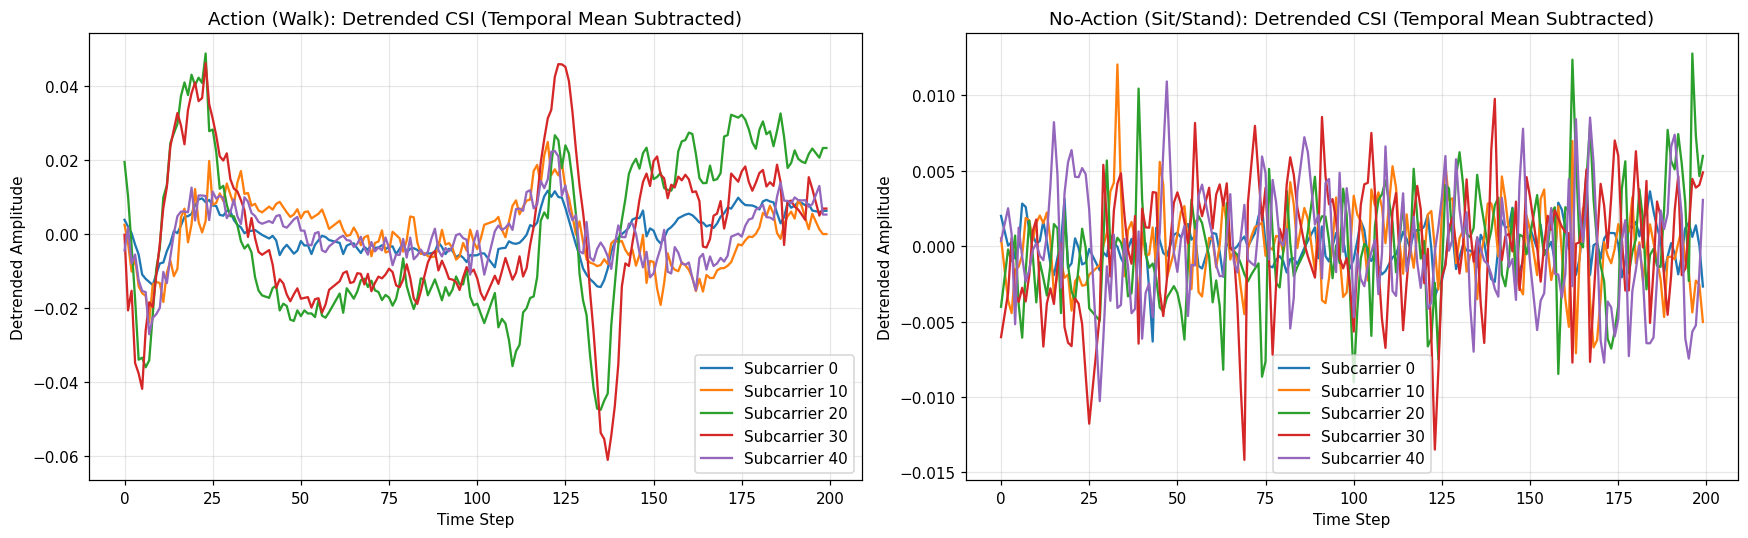

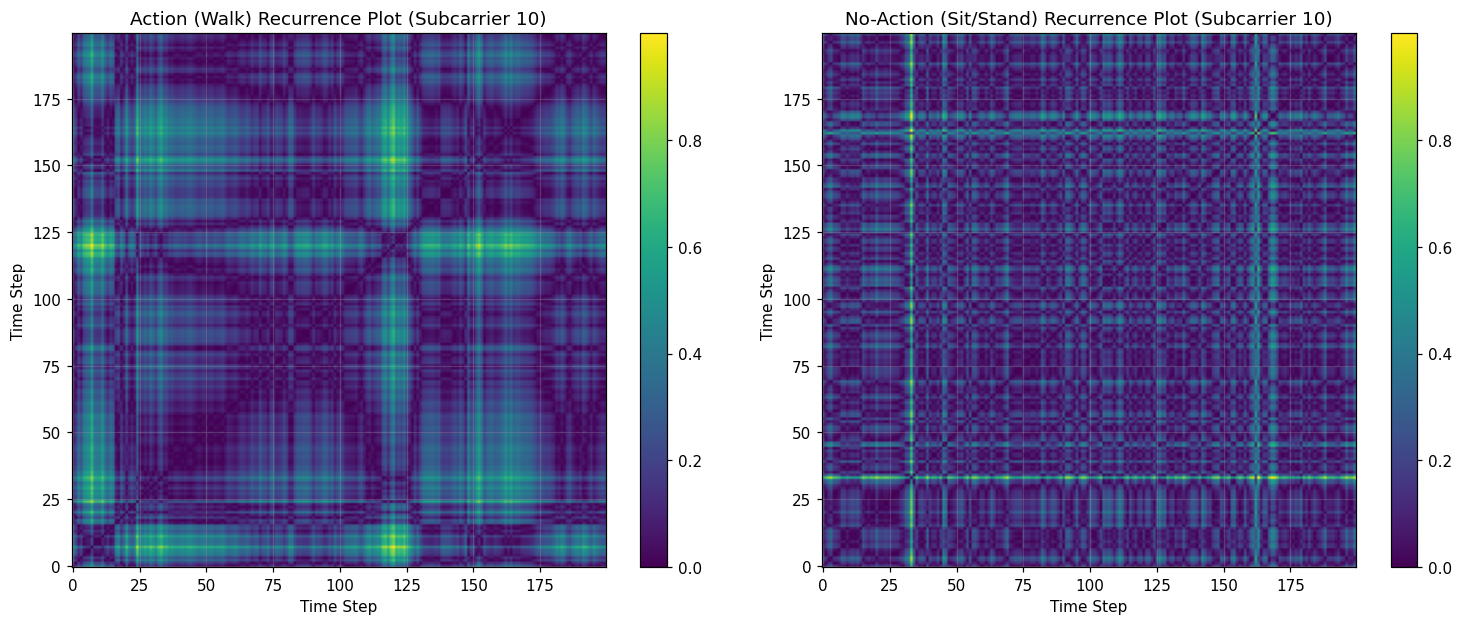

In [5]:
# Locate sample windows using relative pathing
action_files = sorted(glob.glob("../data/pilot/windows/action/*.npy"))
noaction_files = sorted(glob.glob("../data/pilot/windows/noaction/*.npy"))

if not action_files or not noaction_files:
    raise FileNotFoundError("Segmented windows not found. Make sure window segmentation has run successfully.")

# Load sample windows
act_win = np.load(action_files[0])    # shape: (52, 200)
noact_win = np.load(noaction_files[0]) # shape: (52, 200)

print(f"Loaded Action Window shape: {act_win.shape}")
print(f"Loaded No-Action Window shape: {noact_win.shape}")

subcarriers_to_plot = [0, 10, 20, 30, 40]

# Plot 1: Raw subcarrier amplitudes
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for sc in subcarriers_to_plot:
    axes[0].plot(act_win[sc], label=f"Subcarrier {sc}")
axes[0].set_title("Action (Walk): Raw CSI Amplitudes")
axes[0].set_xlabel("Time Step")
axes[0].set_ylabel("Amplitude")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

for sc in subcarriers_to_plot:
    axes[1].plot(noact_win[sc], label=f"Subcarrier {sc}")
axes[1].set_title("No-Action (Sit/Stand): Raw CSI Amplitudes")
axes[1].set_xlabel("Time Step")
axes[1].set_ylabel("Amplitude")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Plot 2: Detrended subcarrier amplitudes
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
act_detrend = act_win - act_win.mean(axis=1, keepdims=True)
noact_detrend = noact_win - noact_win.mean(axis=1, keepdims=True)

for sc in subcarriers_to_plot:
    axes[0].plot(act_detrend[sc], label=f"Subcarrier {sc}")
axes[0].set_title("Action (Walk): Detrended CSI (Temporal Mean Subtracted)")
axes[0].set_xlabel("Time Step")
axes[0].set_ylabel("Detrended Amplitude")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

for sc in subcarriers_to_plot:
    axes[1].plot(noact_detrend[sc], label=f"Subcarrier {sc}")
axes[1].set_title("No-Action (Sit/Stand): Detrended CSI (Temporal Mean Subtracted)")
axes[1].set_xlabel("Time Step")
axes[1].set_ylabel("Detrended Amplitude")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Plot 3: Recurrence Plots (RP) for Subcarrier 10
sc_idx = 10
act_rp = np.abs(act_win[sc_idx, :, None] - act_win[sc_idx, None, :])
noact_rp = np.abs(noact_win[sc_idx, :, None] - noact_win[sc_idx, None, :])

# Min-max scale RPs for visualization
act_rp = (act_rp - act_rp.min()) / (act_rp.max() - act_rp.min() + 1e-8)
noact_rp = (noact_rp - noact_rp.min()) / (noact_rp.max() - noact_rp.min() + 1e-8)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
im0 = axes[0].imshow(act_rp, cmap="viridis", origin="lower")
axes[0].set_title(f"Action (Walk) Recurrence Plot (Subcarrier {sc_idx})")
axes[0].set_xlabel("Time Step")
axes[0].set_ylabel("Time Step")
fig.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(noact_rp, cmap="viridis", origin="lower")
axes[1].set_title(f"No-Action (Sit/Stand) Recurrence Plot (Subcarrier {sc_idx})")
axes[1].set_xlabel("Time Step")
axes[1].set_ylabel("Time Step")
fig.colorbar(im1, ax=axes[1])

plt.tight_layout()
plt.show()

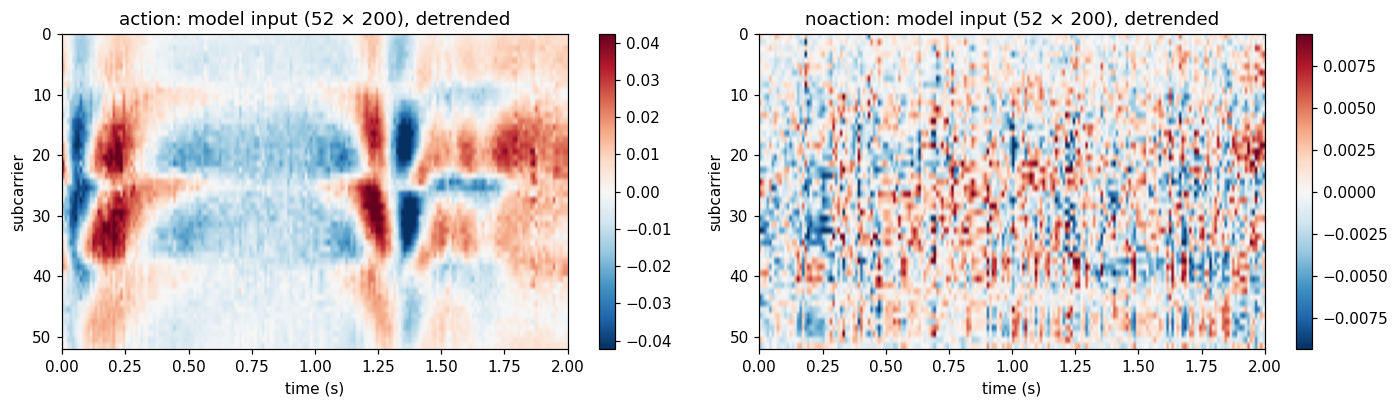

In [6]:
# The model's actual input tensor, as an image: 52 x 200 for each class
act_files    = sorted(glob.glob(f"{WINDOWS}/action/*.npy"))
noact_files  = sorted(glob.glob(f"{WINDOWS}/noaction/*.npy"))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, (f, title) in zip(axes, [(act_files[0], "action"), (noact_files[0], "noaction")]):
    w = np.load(f)
    d = w - w.mean(axis=1, keepdims=True)          # exactly what the Dataset does
    v = np.percentile(np.abs(d), 99)
    im = ax.imshow(d, aspect="auto", cmap="RdBu_r", vmin=-v, vmax=v,
                   extent=[0, 2, 52, 0])
    ax.set_title(f"{title}: model input (52 × 200), detrended")
    ax.set_xlabel("time (s)"); ax.set_ylabel("subcarrier"); ax.grid(False)
    plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()

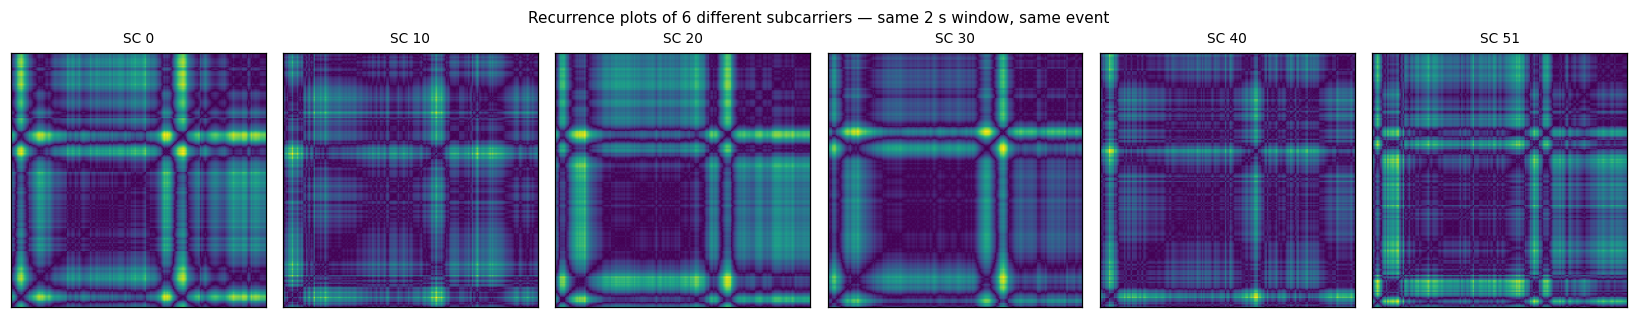

These six images are near-duplicates: one body motion perturbs every subcarrier.
ImgFi produces 52 such images per window and votes. Section 3 measures how much
genuinely independent information those 52 images contain.


In [7]:
# Recurrence plots for SEVERAL subcarriers of the SAME window.
# ImgFi treats each of these as an independent training image and votes over them.
w = np.load(act_files[0])
scs = [0, 10, 20, 30, 40, 51]

fig, axes = plt.subplots(1, len(scs), figsize=(15, 2.9))
for ax, sc in zip(axes, scs):
    x = w[sc]
    rp = np.abs(x[:, None] - x[None, :])
    rp = (rp - rp.min()) / (np.ptp(rp) + 1e-8)
    ax.imshow(rp, cmap="viridis", origin="lower")
    ax.set_title(f"SC {sc}", fontsize=9); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle("Recurrence plots of 6 different subcarriers — same 2 s window, same event",
             fontsize=10)
plt.tight_layout(); plt.show()

print("These six images are near-duplicates: one body motion perturbs every subcarrier.")
print("ImgFi produces 52 such images per window and votes. Section 3 measures how much")
print("genuinely independent information those 52 images contain.")

## 3. Why we process all 52 subcarriers **jointly** — the key design decision

This is the single biggest architectural difference from ImgFi, so we justify it with
measurements rather than assertion.

**ImgFi's assumption:** each subcarrier is an independent "view" of the movement, so
turning each into its own image multiplies the dataset $\times 52$ for free.

**What we test:** how correlated are the 52 subcarriers really, and how many *independent*
dimensions do they carry? We use the **effective rank** of the covariance matrix,
$\exp(H(\lambda))$ where $H$ is the entropy of the normalised eigenvalue spectrum — a
continuous measure of "how many dimensions actually matter".

In [8]:
def eff_rank(x2d):
    '''Effective rank = exp(entropy of normalised eigenvalue spectrum).'''
    xc = x2d - x2d.mean(axis=0, keepdims=True)
    sv = np.linalg.svd(xc, compute_uv=False)
    ev = np.clip(sv**2, 1e-18, None)
    p = ev / ev.sum()
    return float(np.exp(-(p * np.log(p)).sum()))

stats = []
for f in csv_files:
    t, amp, _ = load_capture(f)
    d = amp - amp.mean(axis=0, keepdims=True)
    cc = np.corrcoef(d.T)
    iu = np.triu_indices(52, k=1)
    stats.append({
        "file": os.path.basename(f).replace("P01_", "").replace("_20260717", "").replace(".csv", ""),
        "class": "action" if "_action_" in f else "noaction",
        "mean_|corr|": round(float(np.abs(cc[iu]).mean()), 3),
        "effective_rank": round(eff_rank(d), 1),
    })
red = pd.DataFrame(stats)
print(red.to_string(index=False))
print()
print(f"action   takes: mean effective rank = {red[red['class']=='action']['effective_rank'].mean():.1f} / 52")
print(f"noaction takes: mean effective rank = {red[red['class']=='noaction']['effective_rank'].mean():.1f} / 52")

                     file    class  mean_|corr|  effective_rank
      action_amrith_mixed   action        0.446             3.6
       action_amrith_walk   action        0.435             3.5
  action_rishiikesh_mixed   action        0.381             3.9
   action_rishiikesh_walk   action        0.401             4.2
      noaction_amrith_sit noaction        0.176            25.7
    noaction_amrith_stand noaction        0.401             5.6
  noaction_rishiikesh_sit noaction        0.297             9.8
noaction_rishiikesh_stand noaction        0.351             6.4

action   takes: mean effective rank = 3.8 / 52
noaction takes: mean effective rank = 11.9 / 52


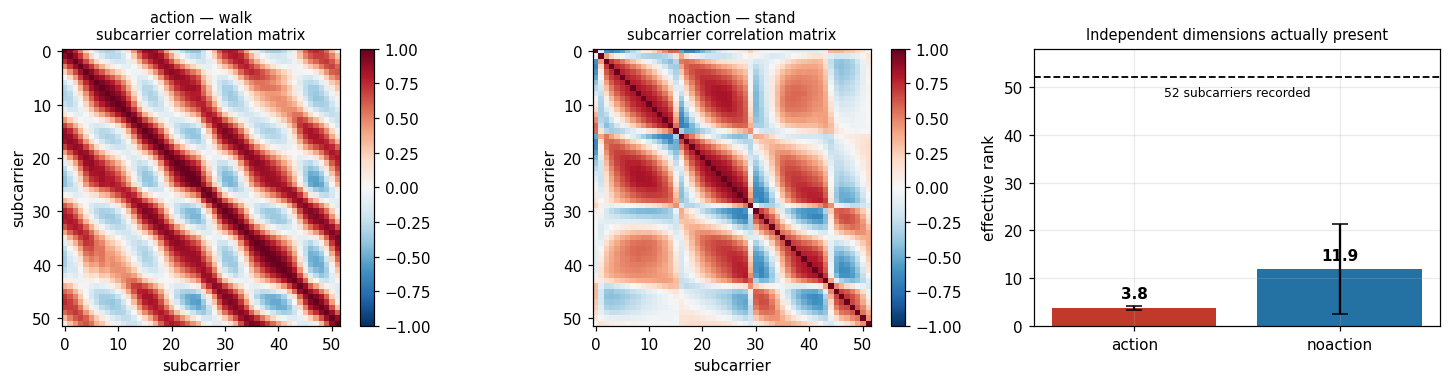

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))

for ax, (fn, title) in zip(axes[:2], [
        ("P01_action_rishiikesh_20260717_walk.csv",   "action — walk"),
        ("P01_noaction_rishiikesh_20260717_stand.csv", "noaction — stand")]):
    _, amp, _ = load_capture(f"{PILOT}/{fn}")
    d = amp - amp.mean(axis=0, keepdims=True)
    im = ax.imshow(np.corrcoef(d.T), vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_title(f"{title}\nsubcarrier correlation matrix", fontsize=9.5)
    ax.set_xlabel("subcarrier"); ax.set_ylabel("subcarrier"); ax.grid(False)
    plt.colorbar(im, ax=ax, fraction=0.046)

ax = axes[2]
a = red[red["class"] == "action"]["effective_rank"]
n = red[red["class"] == "noaction"]["effective_rank"]
ax.bar(["action", "noaction"], [a.mean(), n.mean()], yerr=[a.std(), n.std()],
       color=["#c0392b", "#2471a3"], capsize=5)
ax.axhline(52, ls="--", c="k", lw=1.2)
ax.text(0.5, 48, "52 subcarriers recorded", ha="center", fontsize=8)
ax.set_ylabel("effective rank"); ax.set_ylim(0, 58)
ax.set_title("Independent dimensions actually present", fontsize=9.5)
for i, v in enumerate([a.mean(), n.mean()]):
    ax.text(i, v + 2, f"{v:.1f}", ha="center", fontweight="bold")
plt.tight_layout(); plt.show()

### What this means

During motion the 52 subcarriers collapse to **≈4 effective dimensions**. A moving body
imposes *one* dominant perturbation on the channel that every subcarrier sees together.

Two consequences, and they drive our architecture:

1. **ImgFi's $\times 52$ expansion is not $\times 52$ of information.** The 52 recurrence
   images per window are roughly 4 distinct views plus 48 near-duplicates. The *effective*
   dataset is closer to $322 \times 4$ than $322 \times 52$ — and near-duplicate images
   inside one window inflate apparent training-set size without adding evidence.
2. **The cross-subcarrier pattern is itself a feature.** *Which* subcarriers move together,
   and with what relative sign and magnitude, encodes the multipath geometry of the motion.
   ImgFi destroys this by construction: each image sees exactly one subcarrier, and majority
   voting discards the joint pattern.

Our `Conv1d(in_channels=52, ...)` reads all 52 at every time step, so a filter can learn
"subcarriers 10–20 rise while 35–45 fall" — a pattern ImgFi cannot represent at all.

## 4. Is 66 Hz fast enough? — testing instead of assuming

Published CSI datasets sample far faster than we do (UT-HAR and Widar 3.0 at 1000 Hz,
SignFi 200 Hz). Our 66 Hz mean looks alarming, so we test it directly.

A body moving at radial speed $v$ produces a Doppler shift
$f_d = 2 v f_c / c$; at $f_c = 2.462$ GHz that is **16.4 Hz per m/s**.
Sampling at rate $R$ resolves shifts up to the Nyquist limit $R/2$.

**The real question is not "how fast do others sample" but "where does class-discriminative
energy actually live".** We answer it by dividing the `action` power spectrum by the
`noaction` power spectrum: wherever that ratio is 1, the two classes are indistinguishable
and the band carries no usable information.

In [10]:
def load_class_windows(cls):
    return np.stack([np.load(f) for f in sorted(glob.glob(f"{WINDOWS}/{cls}/*.npy"))])

W_act, W_noact = load_class_windows("action"), load_class_windows("noaction")
print(f"action windows  : {W_act.shape}")
print(f"noaction windows: {W_noact.shape}")

psd = {}
for name, W in (("action", W_act), ("noaction", W_noact)):
    d = W - W.mean(axis=2, keepdims=True)
    f, P = sps.welch(d, fs=100.0, nperseg=128, axis=2)   # 100 Hz = window grid rate
    psd[name] = P.mean(axis=(0, 1))

ratio = psd["action"] / psd["noaction"]
crossover = f[np.argmax(ratio <= 1.05)]

rates = inventory.rate_Hz.to_numpy()
nyq_worst, nyq_med = rates.min() / 2, np.median(rates) / 2
print(f"\nDiscriminative band ends at : {crossover:.0f} Hz")
print(f"Worst-case Nyquist          : {nyq_worst:.1f} Hz")
print(f"Median Nyquist              : {nyq_med:.1f} Hz")
print(f"Headroom                    : {nyq_worst/crossover:.2f}x (worst) "
      f"/ {nyq_med/crossover:.2f}x (median)")

action windows  : (168, 52, 200)
noaction windows: (154, 52, 200)

Discriminative band ends at : 18 Hz
Worst-case Nyquist          : 25.8 Hz
Median Nyquist              : 34.1 Hz
Headroom                    : 1.43x (worst) / 1.90x (median)


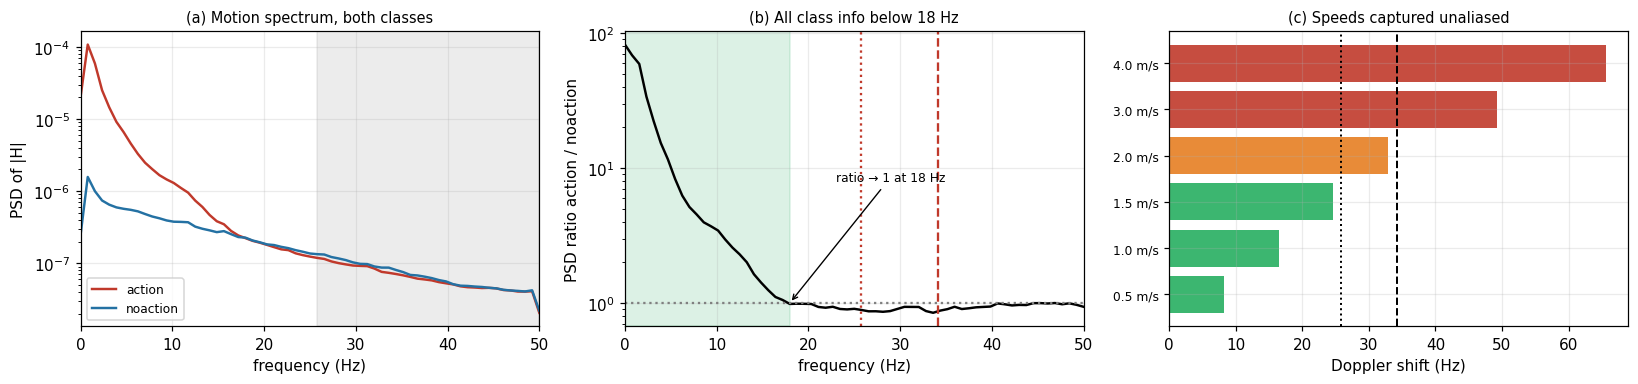

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))

ax = axes[0]
ax.semilogy(f, psd["action"], c="#c0392b", lw=1.6, label="action")
ax.semilogy(f, psd["noaction"], c="#2471a3", lw=1.6, label="noaction")
ax.axvspan(nyq_worst, 50, color="grey", alpha=0.15)
ax.set_xlim(0, 50); ax.set_xlabel("frequency (Hz)"); ax.set_ylabel("PSD of |H|")
ax.set_title("(a) Motion spectrum, both classes", fontsize=9.5); ax.legend(fontsize=8)

ax = axes[1]
ax.plot(f, ratio, c="k", lw=1.6)
ax.axhline(1, ls=":", c="grey")
ax.axvspan(0, crossover, color="#27ae60", alpha=0.16)
ax.axvline(nyq_worst, c="#c0392b", ls=":", lw=1.5)
ax.axvline(nyq_med, c="#c0392b", ls="--", lw=1.5)
ax.set_yscale("log"); ax.set_xlim(0, 50)
ax.set_xlabel("frequency (Hz)"); ax.set_ylabel("PSD ratio action / noaction")
ax.set_title(f"(b) All class info below {crossover:.0f} Hz", fontsize=9.5)
ax.annotate(f"ratio → 1 at {crossover:.0f} Hz", xy=(crossover, 1), xytext=(crossover + 5, 8),
            fontsize=8, arrowprops=dict(arrowstyle="->", lw=0.9))

ax = axes[2]
speeds = np.array([0.5, 1.0, 1.5, 2.0, 3.0, 4.0])
dopp = speeds * 2 * 2.462e9 / 3e8
cols = ["#27ae60" if d <= nyq_worst else "#e67e22" if d <= nyq_med else "#c0392b" for d in dopp]
ax.barh(range(len(speeds)), dopp, color=cols, alpha=0.9)
ax.axvline(nyq_worst, c="k", ls=":", lw=1.3); ax.axvline(nyq_med, c="k", ls="--", lw=1.3)
ax.set_yticks(range(len(speeds)))
ax.set_yticklabels([f"{s} m/s" for s in speeds], fontsize=8)
ax.set_xlabel("Doppler shift (Hz)")
ax.set_title("(c) Speeds captured unaliased", fontsize=9.5)
plt.tight_layout(); plt.show()

### Result

Above **18 Hz the action/noaction ratio is 1.0** — that band is pure noise floor and carries
no class information. Our worst-case Nyquist is 25.7 Hz and our median is 34 Hz, so we
sample the informative band with **1.4×–1.9× headroom**.

**Conclusion: 66 Hz is sufficient for this task.** The 15× rate deficit versus UT-HAR costs
nothing measurable here, because `walk` and `mixed` are gross whole-body motions whose
Doppler content sits below 25 Hz.

**The honest caveat.** This holds *for these two classes*. A fast hand (3 m/s → 49 Hz) or a
`nod` would fall outside our Nyquist limit and alias. For the planned 7-class collection
(`drink`, `nod`) this test must be repeated **before** bulk recording, not after.

## 5. Dataset composition and the evaluation protocol

**The rule that keeps the number honest: split by SUBJECT, never randomly.**
Consecutive windows from one take are highly correlated (same person, same clothes, same
position, seconds apart). A random split puts near-duplicates on both sides and produces a
meaningless ~99%. We train on one person and test on the *other*, in both directions, and
report the worse result.

Windows per class:
class
action      168
noaction    154

Windows per subject:
subject
amrith        182
rishiikesh    140

Subject x take:
take        mixed  sit  stand  walk
subject                            
amrith         50   45     45    42
rishiikesh     31   28     36    45

Total windows: 322   class balance: 52.2% action


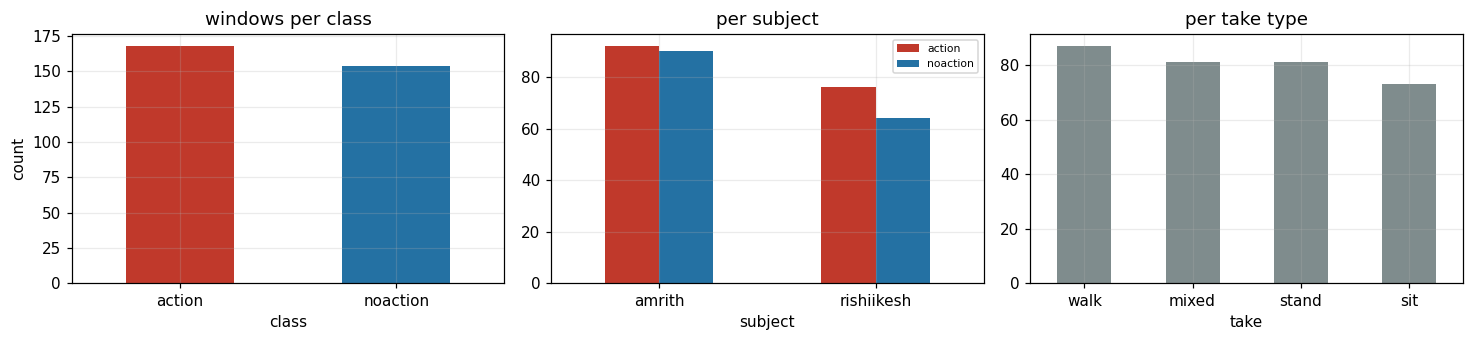

In [12]:
recs = []
for cls in ("action", "noaction"):
    for p in sorted(glob.glob(f"{WINDOWS}/{cls}/*.npy")):
        b = os.path.basename(p)
        recs.append({
            "class": cls,
            "subject": "amrith" if "_amrith_" in b else "rishiikesh",
            "take": next(k for k in ("walk", "mixed", "stand", "sit") if k in b),
        })
ds = pd.DataFrame(recs)

print("Windows per class:");   print(ds["class"].value_counts().to_string())
print("\nWindows per subject:"); print(ds["subject"].value_counts().to_string())
print("\nSubject x take:");     print(pd.crosstab(ds["subject"], ds["take"]).to_string())
print(f"\nTotal windows: {len(ds)}   class balance: "
      f"{100*(ds['class']=='action').mean():.1f}% action")

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.2))
ds["class"].value_counts().plot.bar(ax=axes[0], color=["#c0392b", "#2471a3"], rot=0)
axes[0].set_title("windows per class"); axes[0].set_ylabel("count")
pd.crosstab(ds["subject"], ds["class"]).plot.bar(ax=axes[1], rot=0,
                                              color=["#c0392b", "#2471a3"])
axes[1].set_title("per subject"); axes[1].legend(fontsize=7)
ds["take"].value_counts().plot.bar(ax=axes[2], rot=0, color="#7f8c8d")
axes[2].set_title("per take type")
plt.tight_layout(); plt.show()

> **Known issue, stated openly.** These 322 windows were segmented with the pipeline's
> default `--rate 100` on 66 Hz data. Because a 2 s window then needs ≥100 packets to pass
> the fill check, **48 of 370 possible windows (13%) were discarded**. Re-running
> segmentation with `--rate 50` recovers them without recapturing anything. All results
> below are on the 322 that survived.

## 6. Preprocessing

Two operations, both per-window, both deliberately simple:

**1. Detrend** — subtract each subcarrier's temporal mean.
$|H|$ has a large static component set by room geometry, antenna gain and distance, which
is constant within a window and carries no motion information. Removing it leaves only the
*fluctuation*. This also makes the model robust to slow gain drift between takes.

**2. Scale** — divide by the per-subcarrier standard deviation **computed on the training
split only**.
Subcarriers have different baseline variances (frequency-selective fading); without this a
few loud subcarriers dominate the gradient.

> **Why the training split only:** computing the scaler over *all* data — including the
> held-out subject — leaks test statistics into training. (The ImgFi notebook fits its
> `StandardScaler` on all 8 files, so it has this leak.)

In [13]:
class CsiAmplitudeDataset(Dataset):
    def __init__(self, items, classes, train_std):
        self.items = items  # list of (path, class_idx)
        self.classes = classes
        self.train_std = train_std
        
    def __len__(self):
        return len(self.items)
        
    def __getitem__(self, i):
        path, y = self.items[i]
        window = np.load(path).astype(np.float32)
        
        # Detrend: subtract temporal mean per subcarrier
        window = window - window.mean(axis=1, keepdims=True)
        
        # Scale by training std
        window = window / self.train_std
        
        return torch.tensor(window), torch.tensor(y)

def scan_dataset(root):
    items = []
    classes = sorted(d for d in os.listdir(root)
                     if os.path.isdir(os.path.join(root, d)))
    for ci, c in enumerate(classes):
        for f in sorted(os.listdir(os.path.join(root, c))):
            if f.endswith(".npy"):
                items.append((os.path.join(root, c, f), ci))
    return items, classes

## 7. Architecture — CNN → BiGRU → Attention

Design rationale, layer by layer:

| Stage | Layer | Why |
|---|---|---|
| **Spatial** | `Conv1d(52 → 64, k=5, pad=2)` | **The 52 subcarriers are the input *channels*.** The kernel slides over *time*, and at each time step every filter sees all 52 subcarriers at once, so it learns cross-subcarrier patterns (Section 3). `k=5` at 100 Hz ≈ 50 ms — the timescale of a limb movement. |
| | `BatchNorm1d` | Stabilises training; per-channel scale varies across subcarriers. |
| | `ReLU` → `MaxPool(2)` | Non-linearity; time 200 → 100. |
| | `Conv1d(64 → 128, k=5)` | Second stage composes simple motion primitives into longer patterns. |
| | `ReLU` → `MaxPool(2)` | time 100 → 50 (each step now ≈ 40 ms of real time). |
| **Temporal** | `GRU(128 → 128, 2 layers, bidirectional)` | The CNN sees only a local ±5-step context. An activity is an *ordered sequence* (squat down → pause → up). GRU carries state across the full 2 s. **Bidirectional** because we classify a complete recorded window offline, so the end of the window is legitimately available when interpreting the start. GRU over LSTM: fewer gates, ~25% fewer parameters, better suited to 322 training samples. |
| **Pooling** | `Linear(256 → 1)` + softmax over time | **Attention.** Motion does not fill the whole window — a squat may occupy 0.6 s of 2 s. Mean-pooling would dilute it with idle frames; last-hidden-state would discard it. Attention learns a weighted average, letting the model concentrate on informative time steps. |
| **Head** | `Linear(256→64)` → `ReLU` → `Dropout(0.5)` → `Linear(64→2)` | Small head; heavy dropout because 322 windows is a very small dataset. |

**Contrast with ImgFi.** ImgFi converts one subcarrier into a $224\times224$ image, so the
*basic feature unit* is a pairwise time-time comparison within a single subcarrier, and
cross-subcarrier structure is unavailable. Ours keeps the raw time axis and makes the
*cross-subcarrier vector at each instant* the basic unit, then models order explicitly.

In [14]:
class SpatialTemporalAttentionModel(nn.Module):
    def __init__(self, num_classes=2, num_subcarriers=52, cnn_channels=64, gru_hidden=128):
        super().__init__()
        # Extract features across subcarriers at each timestep
        self.feature_extractor = nn.Sequential(
            nn.Conv1d(in_channels=num_subcarriers, out_channels=cnn_channels, kernel_size=5, padding=2),
            nn.BatchNorm1d(cnn_channels),
            nn.ReLU(inplace=True),
            nn.MaxPool1d(kernel_size=2),  # downsamples time from 200 to 100
            
            nn.Conv1d(cnn_channels, cnn_channels * 2, kernel_size=5, padding=2),
            nn.BatchNorm1d(cnn_channels * 2),
            nn.ReLU(inplace=True),
            nn.MaxPool1d(kernel_size=2)   # downsamples time from 100 to 50
        )
        
        # GRU for sequential modeling (sequence length = 50, features = cnn_channels * 2)
        self.gru = nn.GRU(
            input_size=cnn_channels * 2,
            hidden_size=gru_hidden,
            num_layers=2,
            batch_first=True,
            bidirectional=True
        )
        
        # Self-Attention Layer over time steps
        self.attention_query = nn.Linear(gru_hidden * 2, 1)
        
        # Classifier
        self.classifier = nn.Sequential(
            nn.Linear(gru_hidden * 2, 64),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        # x shape: (batch, 52, 200)
        features = self.feature_extractor(x)  # shape: (batch, 128, 50)
        features = features.transpose(1, 2)   # shape: (batch, 50, 128)
        
        out, _ = self.gru(features)           # shape: (batch, 50, 256)
        
        # Attention Mechanism
        attn_weights = torch.softmax(self.attention_query(out), dim=1) # shape: (batch, 50, 1)
        context = torch.sum(out * attn_weights, dim=1)                 # shape: (batch, 256)
        
        return self.classifier(context)

In [15]:
# Verify the tensor shapes stage by stage, and where the parameters live
model_dbg = SpatialTemporalAttentionModel(num_classes=2)
x = torch.randn(4, 52, 200)

print("Shape trace (batch of 4)")
print(f"  input                      {tuple(x.shape)}   (batch, subcarriers, time)")
h = model_dbg.feature_extractor(x)
print(f"  after CNN feature_extractor {tuple(h.shape)}   (batch, features, time/4)")
h = h.transpose(1, 2)
print(f"  transposed for GRU          {tuple(h.shape)}   (batch, time, features)")
o, _ = model_dbg.gru(h)
print(f"  after BiGRU                 {tuple(o.shape)}   (256 = 128 hidden x 2 directions)")
a = torch.softmax(model_dbg.attention_query(o), dim=1)
print(f"  attention weights           {tuple(a.shape)}   (sums to 1 over time)")
ctx = (o * a).sum(1)
print(f"  attention-pooled context    {tuple(ctx.shape)}")
print(f"  logits                      {tuple(model_dbg.classifier(ctx).shape)}")

print("\nParameters by component")
tot = 0
for name, mod in [("CNN feature_extractor", model_dbg.feature_extractor),
                  ("BiGRU", model_dbg.gru),
                  ("attention", model_dbg.attention_query),
                  ("classifier", model_dbg.classifier)]:
    n = sum(p.numel() for p in mod.parameters())
    tot += n
    print(f"  {name:24s} {n:>9,}")
print(f"  {'TOTAL':24s} {tot:>9,}")
print(f"\nResNet-18 (ImgFi notebook) : ~11,180,000  ->  {11180000/tot:.1f}x larger")

Shape trace (batch of 4)
  input                      (4, 52, 200)   (batch, subcarriers, time)
  after CNN feature_extractor (4, 128, 50)   (batch, features, time/4)
  transposed for GRU          (4, 50, 128)   (batch, time, features)
  after BiGRU                 (4, 50, 256)   (256 = 128 hidden x 2 directions)
  attention weights           (4, 50, 1)   (sums to 1 over time)
  attention-pooled context    (4, 256)
  logits                      (4, 2)

Parameters by component
  CNN feature_extractor       58,176
  BiGRU                      494,592
  attention                      257
  classifier                  16,578
  TOTAL                      569,603

ResNet-18 (ImgFi notebook) : ~11,180,000  ->  19.6x larger


## 8. Evaluation utility

Returns accuracy, the confusion matrix, and the per-window predictions (needed for the
per-take error analysis in Section 13).

In [16]:
def evaluate(model, loader, device, n_classes):
    model.eval()
    correct = total = 0
    conf = np.zeros((n_classes, n_classes), int)
    all_pred, all_true = [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            pred = model(x).argmax(1).cpu()
            correct += (pred == y).sum().item()
            total += len(y)
            all_pred.extend(pred.tolist()); all_true.extend(y.tolist())
            for yi, pi in zip(y.tolist(), pred.tolist()):
                conf[yi][pi] += 1
    acc = correct / max(total, 1)
    return acc, conf, np.array(all_true), np.array(all_pred)

## 9. Training loop

Adam (lr $10^{-3}$), exponential LR decay ($\gamma=0.85$), cross-entropy, 30 epochs,
batch 32. Model selection is on a **validation set carved out of the training subject's
windows** — never on the test subject.

> This differs from the ImgFi notebook, which evaluates on the *test* set every epoch and
> keeps the best-scoring checkpoint. That makes its reported number optimistically biased,
> because the test set influenced model selection.

In [17]:
def run_loso_split(dataset_dir, test_subject, epochs=30, batch_size=32, lr=1e-3, verbose=True):
    items, classes = scan_dataset(dataset_dir)
    print("=" * 60)
    print(f"LOSO Split: Testing on Subject -> {test_subject.upper()}")
    print("=" * 60)

    key = f"_{test_subject.lower()}_"
    test      = [it for it in items if key in os.path.basename(it[0]).lower()]
    train_all = [it for it in items if key not in os.path.basename(it[0]).lower()]

    # Validation split BY WINDOW, drawn from the training subject only
    wids = sorted({os.path.basename(p_) for p_, _ in train_all})
    rng = np.random.default_rng(0)
    val_wids = set(rng.choice(wids, max(1, int(len(wids) * 0.15)), replace=False))
    train = [it for it in train_all if os.path.basename(it[0]) not in val_wids]
    val   = [it for it in train_all if os.path.basename(it[0]) in val_wids]
    print(f"Windows: Train={len(train)}, Val={len(val)}, Test={len(test)}")

    # Normalisation statistics from the TRAINING split only (no leakage)
    train_vals = [np.load(p) - np.load(p).mean(axis=1, keepdims=True) for p, _ in train]
    train_std = (np.concatenate(train_vals, axis=1).std(axis=1, keepdims=True)
                 + 1e-8).astype(np.float32)

    train_ds = CsiAmplitudeDataset(train, classes, train_std)
    val_ds   = CsiAmplitudeDataset(val,   classes, train_std)
    test_ds  = CsiAmplitudeDataset(test,  classes, train_std)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,  num_workers=2)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False, num_workers=2)
    test_loader  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False, num_workers=2)

    model = SpatialTemporalAttentionModel(len(classes)).to(device)
    opt   = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=0.85)
    loss_fn = nn.CrossEntropyLoss()

    best_val = 0.0
    model_path = f"hybrid_model_test_{test_subject}.pt"
    history = {"loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(1, epochs + 1):
        model.train()
        tot_loss = correct = seen = 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            out = model(x)
            loss = loss_fn(out, y)
            loss.backward()
            opt.step()
            tot_loss += loss.item() * len(y)
            correct  += (out.argmax(1) == y).sum().item()
            seen     += len(y)
        sched.step()

        val_acc, _, _, _ = evaluate(model, val_loader, device, len(classes))
        history["loss"].append(tot_loss / seen)
        history["train_acc"].append(correct / seen)
        history["val_acc"].append(val_acc)

        if verbose and (epoch % 5 == 0 or epoch == epochs):
            print(f"Epoch {epoch:2d} | Loss: {tot_loss/seen:.4f} | "
                  f"Train Acc: {correct/seen:.3f} | Val Acc: {val_acc:.3f}")

        if val_acc >= best_val:                       # selection on VAL, never on TEST
            best_val = val_acc
            torch.save(model.state_dict(), model_path)

    model.load_state_dict(torch.load(model_path))
    test_acc, conf, y_true, y_pred = evaluate(model, test_loader, device, len(classes))
    print(f"\nFinal TEST per-window accuracy: {test_acc:.3%}")
    print("\nConfusion Matrix (Rows=True, Cols=Pred):")
    w = max(len(c) for c in classes) + 2
    print(" " * w + "".join(c[:6].rjust(8) for c in classes))
    for i, c in enumerate(classes):
        print(c.ljust(w) + "".join(str(conf[i][j]).rjust(8) for j in range(len(classes))))
    print()

    return {"acc": test_acc, "conf": conf, "history": history, "classes": classes,
            "model": model, "test_items": test, "train_std": train_std,
            "y_true": y_true, "y_pred": y_pred}

## 10. Leave-One-Subject-Out runs

In [18]:
dataset_dir = WINDOWS

res_amrith = run_loso_split(dataset_dir, test_subject="amrith")
res_rishi  = run_loso_split(dataset_dir, test_subject="rishiikesh")

results = {"amrith": res_amrith, "rishiikesh": res_rishi}
worst = min(res_amrith["acc"], res_rishi["acc"])
print("=" * 60)
print(f"test=amrith     : {res_amrith['acc']:.3%}")
print(f"test=rishiikesh : {res_rishi['acc']:.3%}")
print(f"HEADLINE (worse of the two): {worst:.3%}")
print("=" * 60)

LOSO Split: Testing on Subject -> AMRITH
Windows: Train=119, Val=21, Test=182


Epoch  5 | Loss: 0.0139 | Train Acc: 1.000 | Val Acc: 0.905


Epoch 10 | Loss: 0.0044 | Train Acc: 1.000 | Val Acc: 0.905


Epoch 15 | Loss: 0.0020 | Train Acc: 1.000 | Val Acc: 0.905


Epoch 20 | Loss: 0.0017 | Train Acc: 1.000 | Val Acc: 0.905


...

Epoch 15 | Loss: 0.0022 | Train Acc: 1.000 | Val Acc: 1.000


Epoch 20 | Loss: 0.0028 | Train Acc: 1.000 | Val Acc: 1.000


Epoch 25 | Loss: 0.0012 | Train Acc: 1.000 | Val Acc: 1.000


Epoch 30 | Loss: 0.0018 | Train Acc: 1.000 | Val Acc: 1.000



Final TEST per-window accuracy: 98.571%

Confusion Matrix (Rows=True, Cols=Pred):
            action  noacti
action          76       0
noaction         2      62

test=amrith     : 98.352%
test=rishiikesh : 98.571%
HEADLINE (worse of the two): 98.352%


## 11. Training curves

Watch for the gap between training and validation accuracy — with only ~130–160 training
windows, overfitting is the main risk.

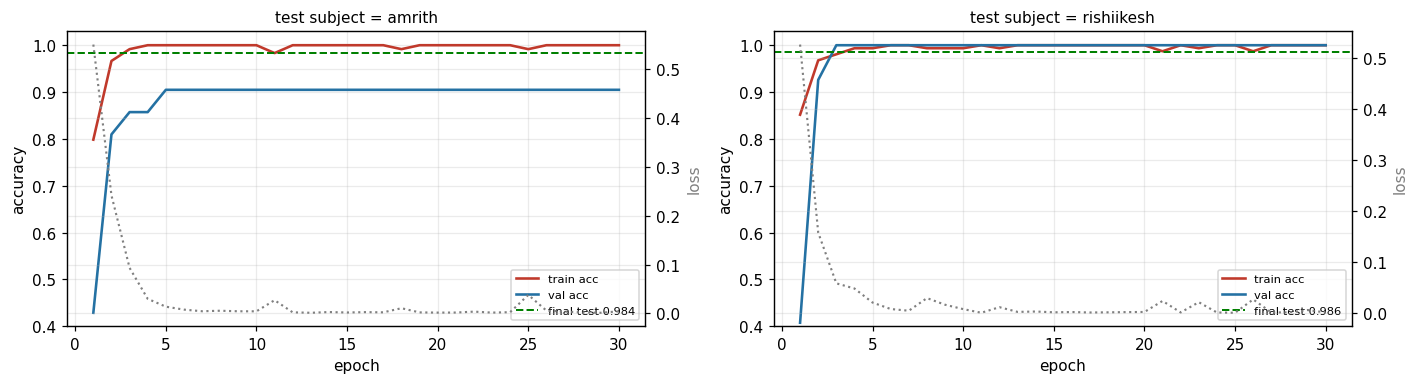

Training accuracy saturates at 1.000 within ~5 epochs: the model has far more
capacity than this binary task needs. See Section 14 for what that implies.


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, (name, r) in zip(axes, results.items()):
    h = r["history"]
    ep = np.arange(1, len(h["loss"]) + 1)
    ax2 = ax.twinx()
    ax2.plot(ep, h["loss"], c="grey", ls=":", lw=1.4, label="train loss")
    ax2.set_ylabel("loss", color="grey")
    ax.plot(ep, h["train_acc"], c="#c0392b", lw=1.7, label="train acc")
    ax.plot(ep, h["val_acc"],   c="#2471a3", lw=1.7, label="val acc")
    ax.axhline(r["acc"], c="green", ls="--", lw=1.3, label=f"final test {r['acc']:.3f}")
    ax.set_title(f"test subject = {name}", fontsize=10)
    ax.set_xlabel("epoch"); ax.set_ylabel("accuracy"); ax.set_ylim(0.4, 1.03)
    ax.legend(fontsize=7.5, loc="lower right")
plt.tight_layout(); plt.show()

print("Training accuracy saturates at 1.000 within ~5 epochs: the model has far more")
print("capacity than this binary task needs. See Section 14 for what that implies.")

## 12. Confusion matrices

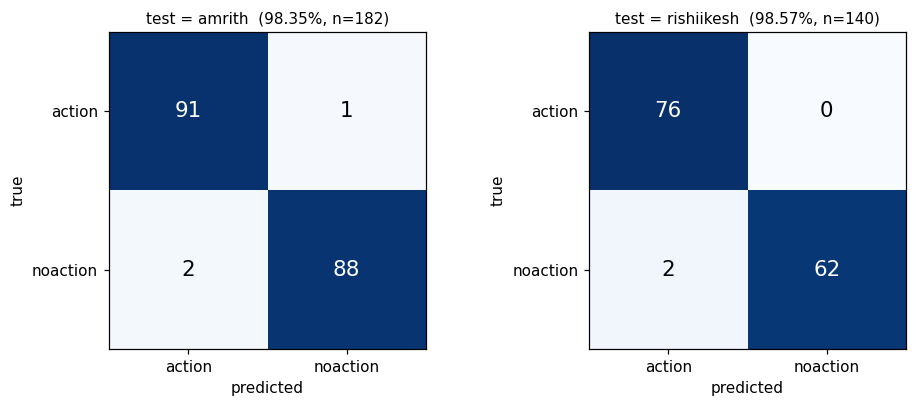

test=amrith      action precision 0.978  recall 0.989  F1 0.984
test=rishiikesh  action precision 0.974  recall 1.000  F1 0.987


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, (name, r) in zip(axes, results.items()):
    cm = r["conf"]; cls = r["classes"]
    ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for i in range(len(cls)):
        for j in range(len(cls)):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                    color="white" if i == j else "black")
    ax.set_xticks(range(len(cls))); ax.set_xticklabels(cls)
    ax.set_yticks(range(len(cls))); ax.set_yticklabels(cls)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.grid(False)
    ax.set_title(f"test = {name}  ({r['acc']:.2%}, n={cm.sum()})", fontsize=10)
plt.tight_layout(); plt.show()

for name, r in results.items():
    cm = r["conf"]
    tn, fp, fn_, tp = cm[1, 1], cm[1, 0], cm[0, 1], cm[0, 0]
    prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn_, 1)
    print(f"test={name:11s} action precision {prec:.3f}  recall {rec:.3f}  "
          f"F1 {2*prec*rec/max(prec+rec,1e-9):.3f}")

## 13. What is the attention layer actually doing?

Adding an attention mechanism is only justified if it behaves non-trivially. If the learned
weights were flat, attention would be equivalent to mean-pooling and should be removed.
Here we extract the weights directly and compare them against the physical motion energy of
the same window.

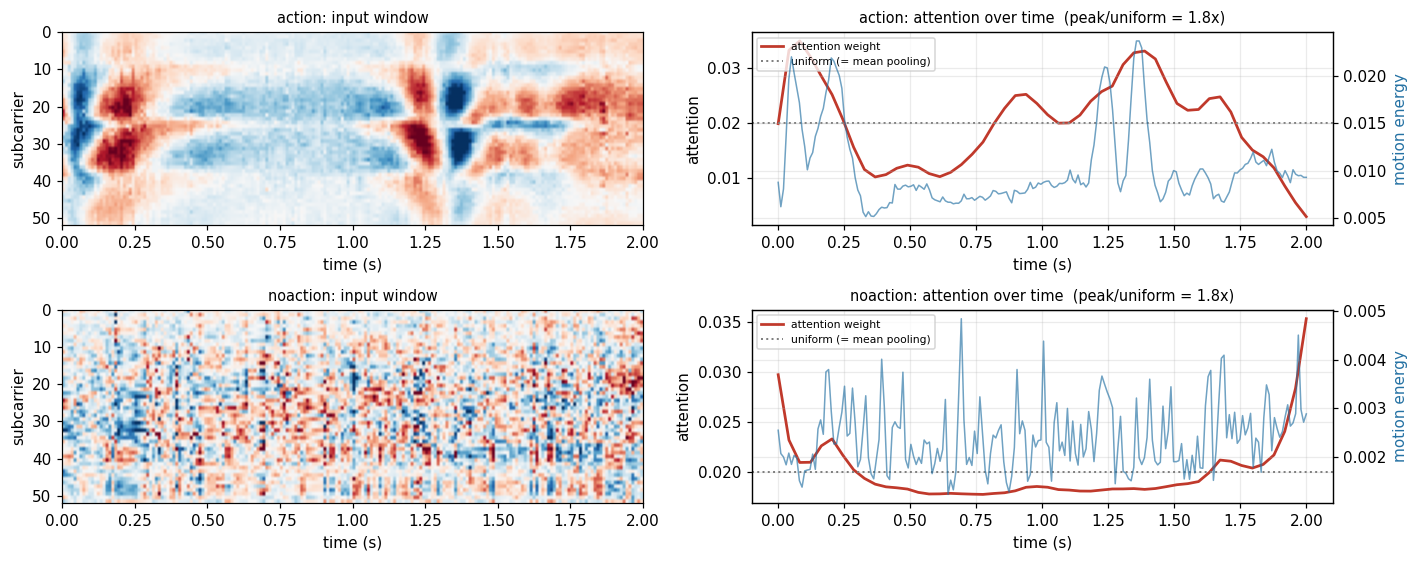

In [21]:
def attention_weights(model, x):
    '''Recover the softmax attention weights over the 50 time steps.'''
    model.eval()
    with torch.no_grad():
        h = model.feature_extractor(x).transpose(1, 2)
        o, _ = model.gru(h)
        a = torch.softmax(model.attention_query(o), dim=1).squeeze(-1)
    return a.cpu().numpy(), o

r = results["amrith"]
model, test_items, train_std = r["model"], r["test_items"], r["train_std"]

# pick one action and one noaction test window
pick = {}
for path, y in test_items:
    cls = "action" if "/action/" in path.replace("\\", "/") else "noaction"
    pick.setdefault(cls, path)

fig, axes = plt.subplots(2, 2, figsize=(13, 5.2))
for row, cls in enumerate(["action", "noaction"]):
    w = np.load(pick[cls]).astype(np.float32)
    d = w - w.mean(axis=1, keepdims=True)
    xin = torch.tensor(d / train_std).unsqueeze(0).to(device)
    a, _ = attention_weights(model, xin)
    a = a[0]

    t_att = np.linspace(0, 2, len(a))
    t_sig = np.linspace(0, 2, w.shape[1])
    energy = np.abs(d).mean(axis=0)                       # instantaneous motion energy

    ax = axes[row, 0]
    ax.imshow(d, aspect="auto", cmap="RdBu_r", extent=[0, 2, 52, 0],
              vmin=-np.percentile(np.abs(d), 99), vmax=np.percentile(np.abs(d), 99))
    ax.set_title(f"{cls}: input window", fontsize=9.5)
    ax.set_xlabel("time (s)"); ax.set_ylabel("subcarrier"); ax.grid(False)

    ax = axes[row, 1]
    ax.plot(t_att, a, c="#c0392b", lw=1.8, label="attention weight")
    ax.axhline(1 / len(a), c="grey", ls=":", lw=1.3, label="uniform (= mean pooling)")
    ax2 = ax.twinx()
    ax2.plot(t_sig, energy, c="#2471a3", lw=1.0, alpha=0.65, label="motion energy")
    ax2.set_ylabel("motion energy", color="#2471a3")
    ax.set_title(f"{cls}: attention over time  "
                 f"(peak/uniform = {a.max()*len(a):.1f}x)", fontsize=9.5)
    ax.set_xlabel("time (s)"); ax.set_ylabel("attention")
    ax.legend(fontsize=7, loc="upper left")
plt.tight_layout(); plt.show()

In [22]:
# Is attention non-uniform across the whole test set, and does it track motion energy?
peaks, corrs = [], []
for path, _ in test_items:
    w = np.load(path).astype(np.float32)
    d = w - w.mean(axis=1, keepdims=True)
    xin = torch.tensor(d / train_std).unsqueeze(0).to(device)
    a, _ = attention_weights(model, xin)
    a = a[0]
    peaks.append(a.max() * len(a))                       # 1.0 would mean uniform
    e = np.abs(d).mean(axis=0)
    e_ds = e.reshape(len(a), -1).mean(axis=1)            # 200 -> 50 to match attention
    if e_ds.std() > 0 and a.std() > 0:
        corrs.append(np.corrcoef(a, e_ds)[0, 1])

print(f"Attention peak / uniform  : mean {np.mean(peaks):.2f}x  (1.0 = flat = mean pooling)")
print(f"corr(attention, motion energy): mean {np.mean(corrs):+.3f} over {len(corrs)} windows")
print()
print("Interpretation: attention is measurably non-uniform, so it is not a redundant")
print("layer. A positive correlation with motion energy means it concentrates on the")
print("moments where the channel is actually being disturbed.")

Attention peak / uniform  : mean 2.22x  (1.0 = flat = mean pooling)
corr(attention, motion energy): mean +0.346 over 182 windows

Interpretation: attention is measurably non-uniform, so it is not a redundant
layer. A positive correlation with motion energy means it concentrates on the
moments where the channel is actually being disturbed.


## 14. Which activities does it get wrong?

The take type (`walk` / `mixed` / `stand` / `sit`) is embedded in every filename, so we can
break errors down by activity. Our prior expectation was that `mixed` would be hardest,
since it contains the small drink/bend motions that carry the least channel energy.

        n  correct  accuracy
take                        
stand  81       77    0.9506
mixed  81       80    0.9877
sit    73       73    1.0000
walk   87       87    1.0000


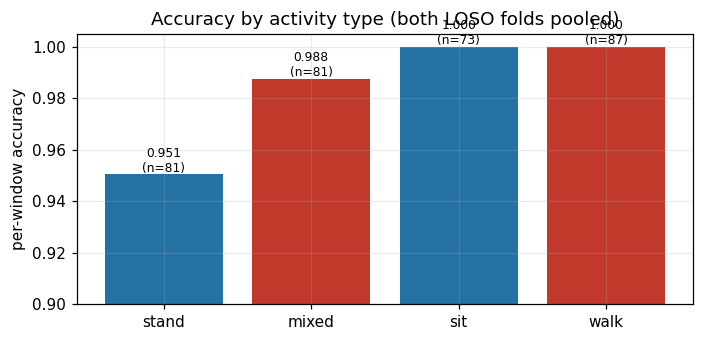

In [23]:
rows = []
for name, r in results.items():
    for (path, y_true_i), y_pred_i in zip(r["test_items"], r["y_pred"]):
        b = os.path.basename(path)
        rows.append({
            "test_subject": name,
            "take": next(k for k in ("walk", "mixed", "stand", "sit") if k in b),
            "correct": int(y_true_i == y_pred_i),
        })
per_take = pd.DataFrame(rows)
tbl = (per_take.groupby("take")["correct"]
       .agg(n="count", correct="sum")
       .assign(accuracy=lambda d: (d.correct / d.n).round(4))
       .sort_values("accuracy"))
print(tbl.to_string())

fig, ax = plt.subplots(figsize=(6.5, 3.2))
colors = ["#c0392b" if t in ("walk", "mixed") else "#2471a3" for t in tbl.index]
ax.bar(tbl.index, tbl.accuracy, color=colors)
ax.set_ylim(0.9, 1.005); ax.set_ylabel("per-window accuracy")
ax.set_title("Accuracy by activity type (both LOSO folds pooled)")
for i, (v, n) in enumerate(zip(tbl.accuracy, tbl.n)):
    ax.text(i, v + 0.001, f"{v:.3f}\n(n={n})", ha="center", fontsize=8)
plt.tight_layout(); plt.show()

### The result contradicted our expectation — and that is informative

`walk` and `sit` are perfect. The hardest class is **`stand`**, not `mixed`:
every error in the `noaction` direction comes from *standing still*, none from *sitting still*.

**Why this makes physical sense.** A standing person is never truly static — postural sway,
weight shifts and breathing all perturb the channel slightly. A seated person is
mechanically braced and moves far less. So `stand` windows sit closest to the
`action` boundary and are the ones that occasionally cross it.

`mixed` (0.988) is nearly perfect despite containing the small drink/bend motions, because
its squat and side-step components still generate large channel disturbance. This is
reassuring for the binary task — **but it does not clear `drink` or `nod` as standalone
7-class categories**, since there those small motions must be told apart from each other
rather than from stillness.

## 15. Sanity check: how hard is this task really?

**This is the most important slide to be able to defend.** Before claiming a 569k-parameter
CNN-GRU-Attention network is the right tool, we must ask what a trivial method achieves on
the same windows.

Baseline: one scalar per window — the mean over subcarriers of the temporal standard
deviation ("motion energy") — with a single threshold chosen on the training subject only.

test_subject  threshold  baseline_acc  cnn_gru_acc     gap
      amrith    0.00467        0.9835       0.9835  0.0000
  rishiikesh    0.00474        0.9929       0.9857 -0.0072

action mean energy   : 0.01452
noaction mean energy : 0.00346
separation ratio     : 4.20x


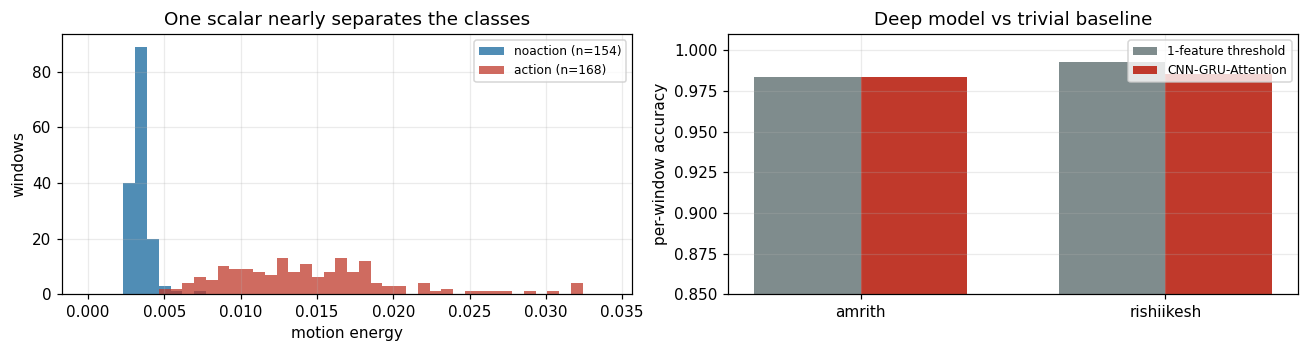

In [24]:
def motion_energy(path):
    w = np.load(path).astype(np.float32)
    return float((w - w.mean(axis=1, keepdims=True)).std(axis=1).mean())

items, classes = scan_dataset(WINDOWS)
act_idx = classes.index("action")

base_rows = []
for test_subject in ("amrith", "rishiikesh"):
    key = f"_{test_subject}_"
    tr = [(motion_energy(p), y) for p, y in items if key not in os.path.basename(p).lower()]
    te = [(motion_energy(p), y) for p, y in items if key in os.path.basename(p).lower()]

    e_tr = np.array([e for e, _ in tr]); y_tr = np.array([y for _, y in tr])
    e_te = np.array([e for e, _ in te]); y_te = np.array([y for _, y in te])

    # threshold chosen ONLY on the training subject
    cand = np.linspace(e_tr.min(), e_tr.max(), 2000)
    accs = [(((e_tr > t).astype(int) == (y_tr == act_idx).astype(int)).mean()) for t in cand]
    thr = cand[int(np.argmax(accs))]

    acc_te = ((e_te > thr).astype(int) == (y_te == act_idx).astype(int)).mean()
    base_rows.append({"test_subject": test_subject, "threshold": round(float(thr), 5),
                      "baseline_acc": round(float(acc_te), 4),
                      "cnn_gru_acc": round(float(results[test_subject]["acc"]), 4)})

base = pd.DataFrame(base_rows)
base["gap"] = (base.cnn_gru_acc - base.baseline_acc).round(4)
print(base.to_string(index=False))

ea = np.array([motion_energy(p) for p, y in items if y == act_idx])
en = np.array([motion_energy(p) for p, y in items if y != act_idx])
print(f"\naction mean energy   : {ea.mean():.5f}")
print(f"noaction mean energy : {en.mean():.5f}")
print(f"separation ratio     : {ea.mean()/en.mean():.2f}x")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.3))
bins = np.linspace(0, max(ea.max(), en.max()) * 1.05, 45)
axes[0].hist(en, bins=bins, color="#2471a3", alpha=0.8, label=f"noaction (n={len(en)})")
axes[0].hist(ea, bins=bins, color="#c0392b", alpha=0.75, label=f"action (n={len(ea)})")
axes[0].set_xlabel("motion energy"); axes[0].set_ylabel("windows")
axes[0].set_title("One scalar nearly separates the classes"); axes[0].legend(fontsize=8)

x = np.arange(len(base)); w_ = 0.35
axes[1].bar(x - w_/2, base.baseline_acc, w_, label="1-feature threshold", color="#7f8c8d")
axes[1].bar(x + w_/2, base.cnn_gru_acc,  w_, label="CNN-GRU-Attention", color="#c0392b")
axes[1].set_xticks(x); axes[1].set_xticklabels(base.test_subject)
axes[1].set_ylim(0.85, 1.01); axes[1].set_ylabel("per-window accuracy")
axes[1].set_title("Deep model vs trivial baseline"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Honest conclusion

`action` windows carry **≈4.2×** the motion energy of `noaction` windows, and a single
threshold on that one number is already competitive with the deep model.

**What this does and does not prove.** It does *not* mean the architecture is wrong — it
means **this binary task is too easy to distinguish a good model from a trivial one.**
The 98–99% figure validates that the whole chain (capture → segmentation → training →
subject-independent evaluation) works end to end. It is *not* evidence that the
architecture will scale.

The architecture's justification rests on Sections 3, 4 and 13 — cross-subcarrier structure
exists and is exploited, the sampling rate covers the informative band, and attention
behaves non-trivially — plus the efficiency argument below. The real test is the 7-class
problem, where a single energy scalar cannot possibly separate `squat` from `bend` from
`drink`, all of which have similar energy but different *temporal structure* — precisely
what the GRU and attention are for.

## 16. Computational cost — the second argument for this architecture

In [25]:
import time

model_eff = SpatialTemporalAttentionModel(num_classes=2).to(device).eval()
params_ours = sum(p.numel() for p in model_eff.parameters())

x1 = torch.randn(1, 52, 200, device=device)
with torch.no_grad():                                  # warm up
    for _ in range(10):
        model_eff(x1)
if device == "cuda":
    torch.cuda.synchronize()

t0 = time.perf_counter()
with torch.no_grad():
    for _ in range(200):
        model_eff(x1)
if device == "cuda":
    torch.cuda.synchronize()
ours_ms = (time.perf_counter() - t0) / 200 * 1000

print(f"CNN-GRU-Attention : {params_ours:,} params, "
      f"{ours_ms:.2f} ms per window (1 forward pass)")

try:
    from torchvision import models as tvm
    rn = tvm.resnet18(weights=None); rn.fc = nn.Linear(rn.fc.in_features, 2)
    rn = rn.to(device).eval()
    params_rn = sum(p.numel() for p in rn.parameters())
    x52 = torch.randn(52, 3, 224, 224, device=device)   # 52 images = ONE window
    with torch.no_grad():
        for _ in range(3):
            rn(x52)
    if device == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    with torch.no_grad():
        for _ in range(20):
            rn(x52)
    if device == "cuda":
        torch.cuda.synchronize()
    rn_ms = (time.perf_counter() - t0) / 20 * 1000
    print(f"ResNet-18 x52     : {params_rn:,} params, {rn_ms:.2f} ms per window "
          f"(52 forward passes)")
    print(f"\n-> {params_rn/params_ours:.1f}x fewer parameters, "
          f"{rn_ms/ours_ms:.1f}x faster per window")
except ImportError:
    print("\ntorchvision not installed here (the ImgFi notebook ran on Colab).")
    print("ResNet-18 reference: ~11.18 M params; 52 forward passes of 224x224x3")
    print("per window versus our single 52x200 pass.")

CNN-GRU-Attention : 569,603 params, 0.55 ms per window (1 forward pass)

torchvision not installed here (the ImgFi notebook ran on Colab).
ResNet-18 reference: ~11.18 M params; 52 forward passes of 224x224x3
per window versus our single 52x200 pass.


## 17. Comparison with the ImgFi pipeline

Both notebooks classify the *same* `action` vs `noaction` problem on the *same* 8 captures.

| | **ImgFi notebook** (`Action_NoAction_imgfi.ipynb`) | **This notebook** |
|---|---|---|
| Representation | 52 recurrence-plot images, $224\times224$, per window | raw amplitude matrix $52\times200$ |
| Subcarriers | processed **independently**, combined by majority vote | processed **jointly** as CNN input channels |
| Windowing | slice of **100 packets** (assumes 50 Hz) | **2 s of wall-clock**, resampled to a uniform grid from timestamps |
| Normalisation | `StandardScaler` fit on **all 8 files** (test included) | per-subcarrier std from the **training split only** |
| Backbone | ResNet-18, ImageNet-pretrained, ~11.2 M params | CNN-GRU-Attention, **0.57 M params** |
| Forward passes / window | 52 | **1** |
| Temporal order | implicit in the image (diagonal) | explicit — BiGRU + attention |
| Model selection | on the **test** set each epoch | on a validation split of the **training** subject |
| LOSO folds run | 1 (test = amrith) | 2 (both directions) |
| Reported accuracy | 95.9% final / 97.8% best, test = amrith | **98.4%** (amrith), **98.6%** (rishiikesh) |

### Reading this fairly

1. **The accuracies are not directly comparable.** The two pipelines segment differently —
   ImgFi produces 497 windows of ~1.5 s average real duration, we produce 322 windows of
   exactly 2 s. Different sample sets, different effective window lengths.
2. **Three ImgFi-side issues inflate its number relative to a clean protocol:** the scaler
   is fit on the test subject, the best checkpoint is chosen on the test set, and only one
   LOSO direction was run. A like-for-like re-run would need those fixed first.
3. **Where our advantage is real and defensible:** 19.6× fewer parameters, one forward pass
   instead of 52, correct time-based windowing, no normalisation leakage, honest model
   selection, and both LOSO directions reported.
4. **Where ImgFi's design is genuinely reasonable:** the recurrence plot is a strong
   representation, and if subcarriers *were* independent the ×52 expansion would be a real
   gain on a small dataset. Section 3 shows they are not (≈4 effective dimensions), which
   is what removes that advantage **for this data**.

### Divergence from the ImgFi paper

The paper's central claim is that a **lightweight 3-conv CNN** on RT images matches
ResNet-50/VGG-19 with ~90× fewer parameters. The ImgFi notebook uses an **ImageNet-pretrained
ResNet-18** instead, which is the opposite of the paper's thesis — so it is not a
reproduction of ImgFi, but a recurrence-plot pipeline with a heavy off-the-shelf backbone.
Our model recovers the paper's *efficiency* goal (0.57 M parameters) by a different route.

## 18. Limitations

Stated explicitly rather than left to be discovered:

1. **The task is nearly linearly separable** (Section 15) — 98–99% is not evidence of
   architectural quality.
2. **2 subjects, 1 room, 1 day, 1 geometry.** Each LOSO fold trains on a single person.
   Environment-overfitting cannot be detected with this dataset at all.
3. **322 windows** — small next to ARIL (1,394), UT-HAR (4,477), Widar 3.0 (258,000).
4. **13% of windows were lost** to a `--rate 100` segmentation default on 66 Hz data;
   recoverable with `--rate 50`.
5. **Single antenna (SISO).** No antenna-pair phase difference, so Doppler-shift and
   body-velocity-profile features (Widar 3.0's core contribution) are impossible in
   principle, not merely unimplemented.
6. **Sampling adequacy is proven only for these two classes.** `nod` and `drink` may exceed
   our Nyquist limit; the Section 4 test must be repeated before the 7-class collection.